In [1]:
%load_ext autoreload
%autoreload 2

import sys
sys.path.append("..")

import numpy as np
import pandas as pd
from sklearn.metrics import average_precision_score, precision_score, recall_score
from src.features import build_features, MODEL_B_DROP

In [2]:
train = pd.read_parquet("../data/processed/train.parquet")
val = pd.read_parquet("../data/processed/val.parquet")

X_train, y_train = build_features(train), train["isFraud"]
X_val, y_val = build_features(val), val["isFraud"]

FEATURES_A = list(X_train.columns)
FEATURES_B = [c for c in FEATURES_A if c not in MODEL_B_DROP]
print("A:", FEATURES_A)
print("B:", FEATURES_B)

A: ['is_transfer', 'amount', 'oldbalanceOrg', 'oldbalanceDest', 'orig_balance_zero', 'dest_balance_zero', 'drains_account', 'amount_to_balance']
B: ['is_transfer', 'amount', 'oldbalanceOrg', 'oldbalanceDest', 'orig_balance_zero', 'dest_balance_zero']


In [3]:
results = []

def evaluate(name, y_true, scores, flags=None):
    row = {"model": name, "pr_auc": round(average_precision_score(y_true, scores), 4)}
    if flags is not None:
        row["precision"] = round(precision_score(y_true, flags, zero_division=0), 4)
        row["recall"] = round(recall_score(y_true, flags), 4)
        row["alerts"] = int(flags.sum())
    results.append(row)
    return row

In [4]:
evaluate("Rule: isFlaggedFraud", y_val, val["isFlaggedFraud"], val["isFlaggedFraud"])
evaluate("Rule: empties account", y_val, X_val["drains_account"], X_val["drains_account"])

{'model': 'Rule: empties account',
 'pr_auc': 0.9899,
 'precision': 1.0,
 'recall': 0.9899,
 'alerts': 489}

In [5]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

def prep_lr(X):
    X = X.copy()
    for c in ["amount", "oldbalanceOrg", "oldbalanceDest"]:
        X[c] = np.log1p(X[c])
    if "amount_to_balance" in X:
        X["amount_to_balance"] = np.log1p(X["amount_to_balance"].fillna(0))
    return X

for label, feats in [("A", FEATURES_A), ("B", FEATURES_B)]:
    lr = make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=1000, class_weight="balanced"),
    )
    lr.fit(prep_lr(X_train[feats]), y_train)
    scores = lr.predict_proba(prep_lr(X_val[feats]))[:, 1]
    evaluate(f"LogReg {label}", y_val, scores)

In [6]:
from xgboost import XGBClassifier

xgb_models = {}
for label, feats in [("A", FEATURES_A), ("B", FEATURES_B)]:
    xgb = XGBClassifier(
        n_estimators=300,
        max_depth=4,
        learning_rate=0.1,
        subsample=0.8,
        colsample_bytree=0.8,
        tree_method="hist",
        eval_metric="aucpr",
        n_jobs=-1,
        random_state=42,
    )
    xgb.fit(X_train[feats], y_train)
    scores = xgb.predict_proba(X_val[feats])[:, 1]
    evaluate(f"XGBoost {label}", y_val, scores)
    xgb_models[label] = xgb

In [7]:
pd.DataFrame(results)

,model,pr_auc,precision,recall,alerts
0,Rule: isFlaggedFraud,0.0013,0.0,0.0000,0.0
1,Rule: empties account,0.9899,1.0,0.9899,489.0
2,LogReg A,1.0000,NaN,NaN,NaN
3,LogReg B,0.0301,NaN,NaN,NaN
4,XGBoost A,1.0000,NaN,NaN,NaN
5,XGBoost B,0.7171,NaN,NaN,NaN


In [8]:
pd.Series(
    xgb_models["B"].feature_importances_, index=FEATURES_B
).sort_values(ascending=False)

dest_balance_zero    0.423582
is_transfer          0.227564
amount               0.120414
oldbalanceOrg        0.106488
oldbalanceDest       0.064897
orig_balance_zero    0.057054
dtype: float32

In [9]:
scores_b = xgb_models["B"].predict_proba(X_val[FEATURES_B])[:, 1]
check = pd.DataFrame({
    "is_fraud": y_val.values,
    "empties_account": X_val["drains_account"].values,
    "score": scores_b,
})
check[check["is_fraud"] == 1].groupby("empties_account")["score"].describe()

,count,mean,std,min,25%,50%,75%,max
empties_account,,,,,,,,
0,5.0,0.994417,0.000000,0.994417,0.994417,0.994417,0.994417,0.994417
1,489.0,0.510402,0.372205,0.003322,0.095854,0.527909,0.908838,0.999673


In [14]:
y = y_val.values
amount = val["amount"].values
s = scores_b

def threshold_table(review_cost, thresholds=None):          # CHANGED: default is now None
    if thresholds is None:                                   # CHANGED: wider search range
        thresholds = np.unique(np.concatenate([
            np.linspace(0.0005, 0.01, 20),   # fine steps below 0.01
            np.linspace(0.01, 0.99, 99),     # the original range
        ]))
    rows = []
    for t in thresholds:
        alert = s >= t
        caught = (y == 1) & alert
        rows.append({
            "threshold": round(t, 4),                        # CHANGED: 4 decimals
            "alerts": int(alert.sum()),
            "frauds_caught": int(caught.sum()),
            "precision": caught.sum() / max(alert.sum(), 1),
            "recall": caught.sum() / y.sum(),
            "missed_loss": amount[(y == 1) & ~alert].sum(),
            "review_cost": review_cost * alert.sum(),
        })
    df_t = pd.DataFrame(rows)
    df_t["total_cost"] = df_t["missed_loss"] + df_t["review_cost"]
    return df_t

no_model_cost = amount[y == 1].sum()
print(f"Cost with no alerts at all (all fraud lost): {no_model_cost:,.0f}")

Cost with no alerts at all (all fraud lost): 656,722,182


In [15]:
best = []
for rc in [100, 1_000, 10_000]:
    t = threshold_table(rc)
    row = t.loc[t["total_cost"].idxmin()].copy()
    row["cost_per_review"] = rc
    best.append(row)
pd.DataFrame(best)[["cost_per_review", "threshold", "alerts", "frauds_caught",
                    "precision", "recall", "total_cost"]]

,cost_per_review,threshold,alerts,frauds_caught,precision,recall,total_cost
9,100.0,0.005,10875.0,490.0,0.045057,0.991903,1228343.90
19,1000.0,0.010,5936.0,470.0,0.079178,0.951417,8334096.17
24,10000.0,0.060,968.0,386.0,0.398760,0.781377,23799774.05


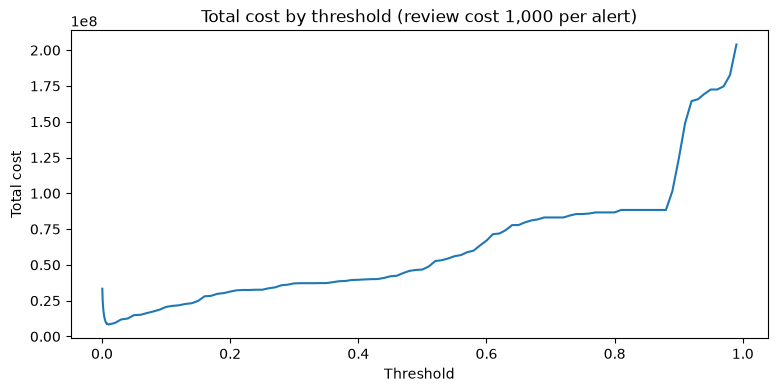

In [16]:
import matplotlib.pyplot as plt
t = threshold_table(1_000)
plt.figure(figsize=(9, 4))
plt.plot(t["threshold"], t["total_cost"])
plt.xlabel("Threshold")
plt.ylabel("Total cost")
plt.title("Total cost by threshold (review cost 1,000 per alert)")
plt.show()

In [17]:
hours = val["step"].nunique()
rows = []
for per_hour in [10, 20, 50, 100]:
    budget = per_hour * hours
    t = np.sort(s)[::-1][budget - 1]      # score of the budget-th highest transaction
    alert = s >= t
    caught = (y == 1) & alert
    rows.append({
        "alerts_per_hour": per_hour,
        "threshold": round(float(t), 4),
        "alerts": int(alert.sum()),
        "frauds_caught": int(caught.sum()),
        "precision": round(caught.sum() / alert.sum(), 3),
        "recall": round(caught.sum() / y.sum(), 3),
        "missed_loss": amount[(y == 1) & ~alert].sum(),
    })
pd.DataFrame(rows)

,alerts_per_hour,threshold,alerts,frauds_caught,precision,recall,missed_loss
0,10,0.2079,500,340,0.680,0.688,31720881.27
1,20,0.0565,1001,386,0.386,0.781,14119774.05
2,50,0.0207,2500,428,0.171,0.866,7202456.89
3,100,0.0119,5000,463,0.093,0.937,3141454.28


In [18]:
import os, json
os.makedirs("../models", exist_ok=True)
xgb_models["B"].save_model("../models/xgb_model_b.json")
with open("../models/thresholds.json", "w") as f:
    json.dump({
        "main_cost_1000": 0.010,
        "capacity_20_per_hour": 0.0565,
    }, f, indent=2)